<a href="https://colab.research.google.com/github/bellDataSc/Analise-de-Sentimentos/blob/main/InferenciaLaya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Testando o Laya em português

No meu estudo com os roteiros de Rick and Morty, analisei sentimentos com três dicionários: AFINN, Bing e NRC. O método é transparente e fácil de auditar, mas tem um limite que eu mesma deixei documentado: dicionário não entende negação. A palavra positiva continua contando, mesmo com um "não" na frente.

Por isso, um dos próximos passos que anotei no README era comparar os léxicos com um modelo contextual. O Laya me pareceu um bom candidato.

O Laya é um modelo de decisão com pesos abertos. Ele recebe um texto e uma pergunta tipada (escolher entre opções, dar uma nota ou responder sim ou não) e devolve a decisão com as probabilidades, em uma única passada pelo modelo. Como ele não gera texto, não existe resposta para interpretar nem formato para consertar.

Antes de pensar em levar o modelo para os roteiros, eu quis ver como ele se sai com frases curtas em português. Montei três testes, com dez frases cada:

1. **Sentimento**: positivo, neutro ou negativo.
2. **Categoria de atendimento**: pagamento, conta, técnico, entrega ou cancelamento.
3. **Significado**: duas frases dizem a mesma coisa?

Dez frases não são um benchmark. Isto aqui é uma primeira conversa com o modelo, e eu prestei mais atenção nos erros do que nos acertos.

Repositório do Laya: https://github.com/NandhaKishorM/laya

## Como este notebook roda

Rodei o Laya no Colab, com GPU T4 e a versão 0.4.13 da biblioteca, em 22/10/2026. As probabilidades que o modelo devolveu para cada frase estão em `resultados/laya_colab_2026-10-22.csv`, e a análise lê desse arquivo. Assim, quem abre o notebook vê os mesmos números que eu vi, sem precisar baixar o modelo.

Para rodar o modelo de novo, troque `RODAR_MODELO` para `True`. O notebook instala a biblioteca, passa as 30 frases pelo Laya e salva um arquivo novo em `resultados/`, com a data do dia. Com GPU fica mais rápido.

In [1]:
import importlib.util
import os
import subprocess
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

RODAR_MODELO = False
VERSAO_LAYA = "0.4.13"
ARQUIVO = Path("resultados/laya_colab_2026-10-22.csv")
URL = "https://raw.githubusercontent.com/bellDataSc/Analise-de-Sentimentos/main/resultados/laya_colab_2026-10-22.csv"
LIMITE_REVISAO = 0.60

pd.set_option("display.max_colwidth", None)

## As frases

São as mesmas trinta frases do teste original, cada uma com o rótulo que eu esperava. As perguntas também ficaram iguais, palavra por palavra, porque mudar o texto da pergunta pode mudar a resposta do modelo.

In [2]:
SENTIMENTO = [
    ("Adorei o atendimento, foram muito atenciosos.", "positivo"),
    ("O produto chegou antes do prazo e funciona perfeitamente.", "positivo"),
    ("Estou muito satisfeita com a qualidade do serviço.", "positivo"),
    ("A experiência foi excelente, voltaria a comprar.", "positivo"),
    ("O produto chegou, mas ainda não tive tempo de testá-lo.", "neutro"),
    ("A entrega está prevista para amanhã.", "neutro"),
    ("O aplicativo foi atualizado ontem.", "neutro"),
    ("O atendimento foi péssimo e demoraram horas para responder.", "negativo"),
    ("Estou muito decepcionada com a qualidade do produto.", "negativo"),
    ("O pedido chegou quebrado e ninguém resolveu o problema.", "negativo"),
]

CATEGORIA = [
    ("Meu cartão foi cobrado duas vezes pela mesma compra.", "pagamento"),
    ("Gostaria de solicitar o reembolso da minha última cobrança.", "pagamento"),
    ("Não consigo entrar na minha conta porque esqueci minha senha.", "conta"),
    ("Como posso alterar o endereço de e-mail cadastrado?", "conta"),
    ("O aplicativo fecha sozinho sempre que tento abrir.", "tecnico"),
    ("Estou recebendo uma mensagem de erro ao tentar fazer o pagamento.", "tecnico"),
    ("Meu pedido ainda não chegou. Vocês podem verificar o status da entrega?", "entrega"),
    ("Gostaria de saber quando minha encomenda será entregue.", "entrega"),
    ("Quero cancelar minha assinatura antes da próxima cobrança.", "cancelamento"),
    ("Não quero mais utilizar o serviço e gostaria de encerrar minha conta.", "cancelamento"),
]

SIMILARIDADE = [
    ("O paciente está com febre.", "O paciente apresenta temperatura corporal elevada.", "alta"),
    ("O médico prescreveu antibióticos para o paciente.", "O paciente recebeu uma prescrição de antibióticos.", "alta"),
    ("A consulta foi cancelada.", "A consulta não acontecerá conforme planejado.", "alta"),
    ("O paciente está com febre.", "O paciente está com dor de cabeça.", "baixa"),
    ("O paciente recebeu antibióticos.", "O paciente foi tratado por uma infecção.", "média"),
    ("O hospital realizou uma cirurgia.", "O paciente passou por um procedimento médico.", "média"),
    ("O paciente está com febre.", "O paciente não apresenta febre.", "baixa"),
    ("O paciente recebeu antibióticos.", "O paciente recebeu analgésicos.", "baixa"),
    ("O paciente recebeu alta do hospital.", "O paciente foi internado no hospital.", "baixa"),
    ("O médico solicitou um exame de sangue.", "O paciente comprou um computador novo.", "baixa"),
]

PERGUNTA_SENTIMENTO = {
    "type": "choice",
    "instructions": "Qual é o sentimento predominante no texto?",
    "criteria": {
        "positivo": "O texto expressa um sentimento ou opinião positiva.",
        "neutro": "O texto é neutro e não expressa uma opinião ou emoção claramente positiva ou negativa.",
        "negativo": "O texto expressa um sentimento ou opinião negativa.",
    },
}

PERGUNTA_CATEGORIA = {
    "type": "choice",
    "instructions": "Qual é a principal categoria ou intenção expressa no texto?",
    "criteria": {
        "pagamento": "Problemas ou solicitações relacionados a cobranças, pagamentos ou reembolsos.",
        "conta": "Problemas ou solicitações relacionados à conta, login, senha ou dados pessoais.",
        "tecnico": "Problemas técnicos, erros, bugs ou falhas no aplicativo ou sistema.",
        "entrega": "Problemas ou perguntas relacionados a pedidos, entregas ou envio.",
        "cancelamento": "Solicitações para cancelar uma assinatura, serviço ou conta.",
    },
}

PERGUNTA_SIMILARIDADE = {
    "type": "noul",
    "instructions": "As duas frases têm o mesmo significado?",
}

TESTES = {
    "sentimento": ("sentiment", PERGUNTA_SENTIMENTO, [(texto, "", esperado) for texto, esperado in SENTIMENTO]),
    "categoria": ("categoria", PERGUNTA_CATEGORIA, [(texto, "", esperado) for texto, esperado in CATEGORIA]),
    "similaridade": ("similar", PERGUNTA_SIMILARIDADE, SIMILARIDADE),
}

In [3]:
def rodar_laya():
    os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
    os.environ.setdefault("HF_HUB_VERBOSITY", "error")
    if importlib.util.find_spec("laya") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"laya=={VERSAO_LAYA}"], check=True)
    from laya import Router

    router = Router()
    linhas = []
    for teste, (chave, pergunta, casos) in TESTES.items():
        for caso, (texto, texto_b, esperado) in enumerate(casos, 1):
            entrada = f"Frase A: {texto}\nFrase B: {texto_b}" if texto_b else texto
            resposta = router.predict(entrada, {chave: pergunta})["answers"][chave]
            if pergunta["type"] == "noul":
                probabilidades = {"sim": resposta["noul"]}
            else:
                probabilidades = resposta["probabilities"]
            for opcao, probabilidade in probabilidades.items():
                linhas.append({
                    "teste": teste,
                    "caso": caso,
                    "texto": texto,
                    "texto_b": texto_b,
                    "esperado": esperado,
                    "opcao": opcao,
                    "probabilidade": probabilidade,
                })
    return pd.DataFrame(linhas)


if RODAR_MODELO:
    resultados = rodar_laya()
    ARQUIVO = Path(f"resultados/laya_{date.today():%Y-%m-%d}.csv")
    ARQUIVO.parent.mkdir(exist_ok=True)
    resultados.to_csv(ARQUIVO, index=False)
    fonte = ARQUIVO
else:
    fonte = ARQUIVO if ARQUIVO.exists() else URL
    resultados = pd.read_csv(fonte, keep_default_na=False)

definidas = {(teste, texto, texto_b) for teste, (_, _, casos) in TESTES.items() for texto, texto_b, _ in casos}
no_arquivo = set(resultados[["teste", "texto", "texto_b"]].itertuples(index=False, name=None))
if definidas != no_arquivo:
    raise ValueError("As frases do arquivo não batem com as definidas acima. Rode o modelo de novo com RODAR_MODELO = True.")

print(f"{len(no_arquivo)} frases lidas de {fonte}")

30 frases lidas de resultados/laya_colab_2026-10-22.csv


In [4]:
def pct(valor):
    return f"{valor:.2%}".replace(".", ",")


def decisoes(teste):
    dados = resultados[resultados["teste"] == teste].sort_values(["caso", "probabilidade"], ascending=[True, False])
    linhas = []
    for _, grupo in dados.groupby("caso"):
        escolhida, segunda = grupo.iloc[0], grupo.iloc[1]
        linhas.append({
            "Frase": escolhida["texto"],
            "Eu esperava": escolhida["esperado"],
            "Laya": escolhida["opcao"],
            "Confiança": escolhida["probabilidade"],
            "Segunda opção": f"{segunda['opcao']} ({pct(segunda['probabilidade'])})",
            "Acertou": escolhida["opcao"] == escolhida["esperado"],
        })
    return pd.DataFrame(linhas, index=range(1, len(linhas) + 1))


def mostrar(tabela):
    return tabela.assign(**{
        "Confiança": tabela["Confiança"].map(pct),
        "Acertou": tabela["Acertou"].map({True: "sim", False: "não"}),
    })

## 1. Sentimento

A primeira pergunta foi a mais simples: qual é o sentimento predominante no texto?

Na tabela, a coluna **Segunda opção** mostra a alternativa que ficou logo atrás da escolhida. É ali que a dúvida do modelo aparece.

In [5]:
sentimento = decisoes("sentimento")
mostrar(sentimento)

,Frase,Eu esperava,Laya,Confiança,Segunda opção,Acertou
1,"Adorei o atendimento, foram muito atenciosos.",positivo,neutro,"54,13%","positivo (44,81%)",não
2,O produto chegou antes do prazo e funciona perfeitamente.,positivo,positivo,"94,84%","neutro (4,83%)",sim
3,Estou muito satisfeita com a qualidade do serviço.,positivo,positivo,"99,56%","neutro (0,42%)",sim
4,"A experiência foi excelente, voltaria a comprar.",positivo,positivo,"83,92%","neutro (14,35%)",sim
5,"O produto chegou, mas ainda não tive tempo de testá-lo.",neutro,negativo,"48,79%","neutro (42,76%)",não
6,A entrega está prevista para amanhã.,neutro,neutro,"79,20%","negativo (12,48%)",sim
7,O aplicativo foi atualizado ontem.,neutro,negativo,"58,26%","neutro (27,46%)",não
8,O atendimento foi péssimo e demoraram horas para responder.,negativo,negativo,"99,48%","neutro (0,43%)",sim
9,Estou muito decepcionada com a qualidade do produto.,negativo,negativo,"99,85%","neutro (0,13%)",sim
10,O pedido chegou quebrado e ninguém resolveu o problema.,negativo,negativo,"93,42%","neutro (4,08%)",sim


Sete de dez. O que me chamou atenção foi onde os erros caíram: os três ficaram abaixo de 60% de confiança, e o acerto menos confiante ficou em 79,20%. Neste teste, a confiança separou bem o que dava para aceitar do que pedia revisão.

O erro que eu não esperava foi "Adorei o atendimento, foram muito atenciosos.", que saiu neutro. Os outros dois são frases neutras que viraram negativas. "O aplicativo foi atualizado ontem." não tem nada de negativo e, mesmo assim, ficou com 58,26% para negativo. Já "O produto chegou, mas ainda não tive tempo de testá-lo." eu consigo defender: o "mas" e o "ainda não" carregam um pouco de frustração, e o modelo ficou dividido entre negativo e neutro.

## 2. Categoria de atendimento

Aqui cada frase é um pedido de cliente, e a pergunta é para qual área ele deve ir. São cinco categorias, com duas frases para cada uma.

In [6]:
categoria = decisoes("categoria")
mostrar(categoria)

,Frase,Eu esperava,Laya,Confiança,Segunda opção,Acertou
1,Meu cartão foi cobrado duas vezes pela mesma compra.,pagamento,pagamento,"92,39%","conta (3,92%)",sim
2,Gostaria de solicitar o reembolso da minha última cobrança.,pagamento,pagamento,"64,06%","cancelamento (35,87%)",sim
3,Não consigo entrar na minha conta porque esqueci minha senha.,conta,conta,"93,90%","tecnico (5,33%)",sim
4,Como posso alterar o endereço de e-mail cadastrado?,conta,cancelamento,"37,06%","tecnico (34,81%)",não
5,O aplicativo fecha sozinho sempre que tento abrir.,tecnico,tecnico,"97,26%","conta (0,82%)",sim
6,Estou recebendo uma mensagem de erro ao tentar fazer o pagamento.,tecnico,pagamento,"99,95%","tecnico (0,04%)",não
7,Meu pedido ainda não chegou. Vocês podem verificar o status da entrega?,entrega,entrega,"99,99%","tecnico (0,01%)",sim
8,Gostaria de saber quando minha encomenda será entregue.,entrega,entrega,"99,98%","tecnico (0,01%)",sim
9,Quero cancelar minha assinatura antes da próxima cobrança.,cancelamento,cancelamento,"100,00%","pagamento (0,00%)",sim
10,Não quero mais utilizar o serviço e gostaria de encerrar minha conta.,cancelamento,cancelamento,"99,97%","tecnico (0,02%)",sim


Oito de dez, e os dois erros não têm nada a ver um com o outro.

"Como posso alterar o endereço de e-mail cadastrado?" foi para cancelamento, com 37,06%. O modelo se dividiu entre cancelamento, técnico e conta, e a confiança baixa já avisava que a resposta não era firme.

O outro erro é o meu preferido. Para "Estou recebendo uma mensagem de erro ao tentar fazer o pagamento.", eu esperava técnico. O Laya respondeu pagamento, com 99,95%. Olhando de novo, a frase é as duas coisas: um erro técnico no pagamento. O problema estava nas minhas categorias, que se sobrepõem, e não no modelo. É o tipo de erro que nenhum limite de confiança pega, porque o modelo não está em dúvida.

Vale olhar também um acerto: "Gostaria de solicitar o reembolso da minha última cobrança." foi para pagamento, mas com 35,87% para cancelamento. Reembolso e cancelamento costumam andar juntos, e isso aparece nas probabilidades.

## 3. Mesmo significado?

O Laya não é um modelo de embeddings, então não dá para calcular similaridade de cosseno. O caminho foi transformar a comparação em uma pergunta de sim ou não: "As duas frases têm o mesmo significado?". A tabela mostra a probabilidade do sim.

In [7]:
pares = resultados[resultados["teste"] == "similaridade"].sort_values("caso")
pd.DataFrame(
    {
        "Frase A": pares["texto"].to_numpy(),
        "Frase B": pares["texto_b"].to_numpy(),
        "Eu esperava": pares["esperado"].to_numpy(),
        "Mesmo significado": pares["probabilidade"].map(pct).to_numpy(),
    },
    index=range(1, len(pares) + 1),
)

,Frase A,Frase B,Eu esperava,Mesmo significado
1,O paciente está com febre.,O paciente apresenta temperatura corporal elevada.,alta,"93,44%"
2,O médico prescreveu antibióticos para o paciente.,O paciente recebeu uma prescrição de antibióticos.,alta,"99,63%"
3,A consulta foi cancelada.,A consulta não acontecerá conforme planejado.,alta,"28,95%"
4,O paciente está com febre.,O paciente está com dor de cabeça.,baixa,"88,81%"
5,O paciente recebeu antibióticos.,O paciente foi tratado por uma infecção.,média,"85,25%"
6,O hospital realizou uma cirurgia.,O paciente passou por um procedimento médico.,média,"99,51%"
7,O paciente está com febre.,O paciente não apresenta febre.,baixa,"2,95%"
8,O paciente recebeu antibióticos.,O paciente recebeu analgésicos.,baixa,"95,25%"
9,O paciente recebeu alta do hospital.,O paciente foi internado no hospital.,baixa,"36,69%"
10,O médico solicitou um exame de sangue.,O paciente comprou um computador novo.,baixa,"12,87%"


O caso que eu mais queria ver era a negação, e ele foi bem: "O paciente está com febre." contra "O paciente não apresenta febre." ficou com 2,95% de chance de ser a mesma coisa. É justamente o que um dicionário não consegue fazer.

Mas apareceu outro padrão. Frases sobre o mesmo assunto, com sentidos diferentes, receberam probabilidade alta: febre e dor de cabeça ficaram com 88,81%, antibióticos e analgésicos com 95,25%. E uma paráfrase de verdade, "A consulta foi cancelada." e "A consulta não acontecerá conforme planejado.", ficou com só 28,95%. Minha leitura: nesse formato, o modelo está mais perto de responder "as frases falam do mesmo assunto?" do que "as frases dizem a mesma coisa?".

Também tem um problema de desenho meu. Eu esperava três níveis (alta, média, baixa) e fiz uma pergunta de sim ou não. Para medir grau, o Laya tem o tipo `score`, que fica para a próxima rodada.

## Fechando

O que eu levo desta primeira conversa:

- **A confiança ajuda, mas não resolve tudo.** Olhando para trás, revisar tudo o que ficou abaixo de 60% teria pegado quatro dos cinco erros de classificação, sem mandar nenhum acerto para revisão. Com dez frases por teste, isso é uma pista, não uma regra.
- **O erro que sobrou era de desenho, não de modelo.** Categorias que se sobrepõem geram erro com confiança alta, e isso se resolve escrevendo melhor as opções, não mexendo no limite.
- **Negação ele entende.** Era a dúvida que me trouxe até aqui.
- **Próximos passos:** usar o tipo `score` para medir grau de semelhança, aumentar o número de frases e, aí sim, rodar o Laya nos roteiros de Rick and Morty para comparar com os léxicos.

A tabela e o gráfico abaixo juntam os dois testes de classificação. No gráfico, cada ponto é uma frase, posicionada pela confiança que o Laya deu para a própria resposta.

In [8]:
classificacao = pd.concat([sentimento.assign(Teste="Sentimento"), categoria.assign(Teste="Categoria")])
confianca_acertos = classificacao[classificacao["Acertou"]].groupby("Teste", sort=False)["Confiança"]
confianca_erros = classificacao[~classificacao["Acertou"]].groupby("Teste", sort=False)["Confiança"]

pd.DataFrame({
    "Acertos": confianca_acertos.size(),
    "Erros": confianca_erros.size(),
    "Menor confiança num acerto": confianca_acertos.min().map(pct),
    "Maior confiança num erro": confianca_erros.max().map(pct),
})

,Acertos,Erros,Menor confiança num acerto,Maior confiança num erro
Teste,,,,
Sentimento,7,3,"79,20%","58,26%"
Categoria,8,2,"64,06%","99,95%"


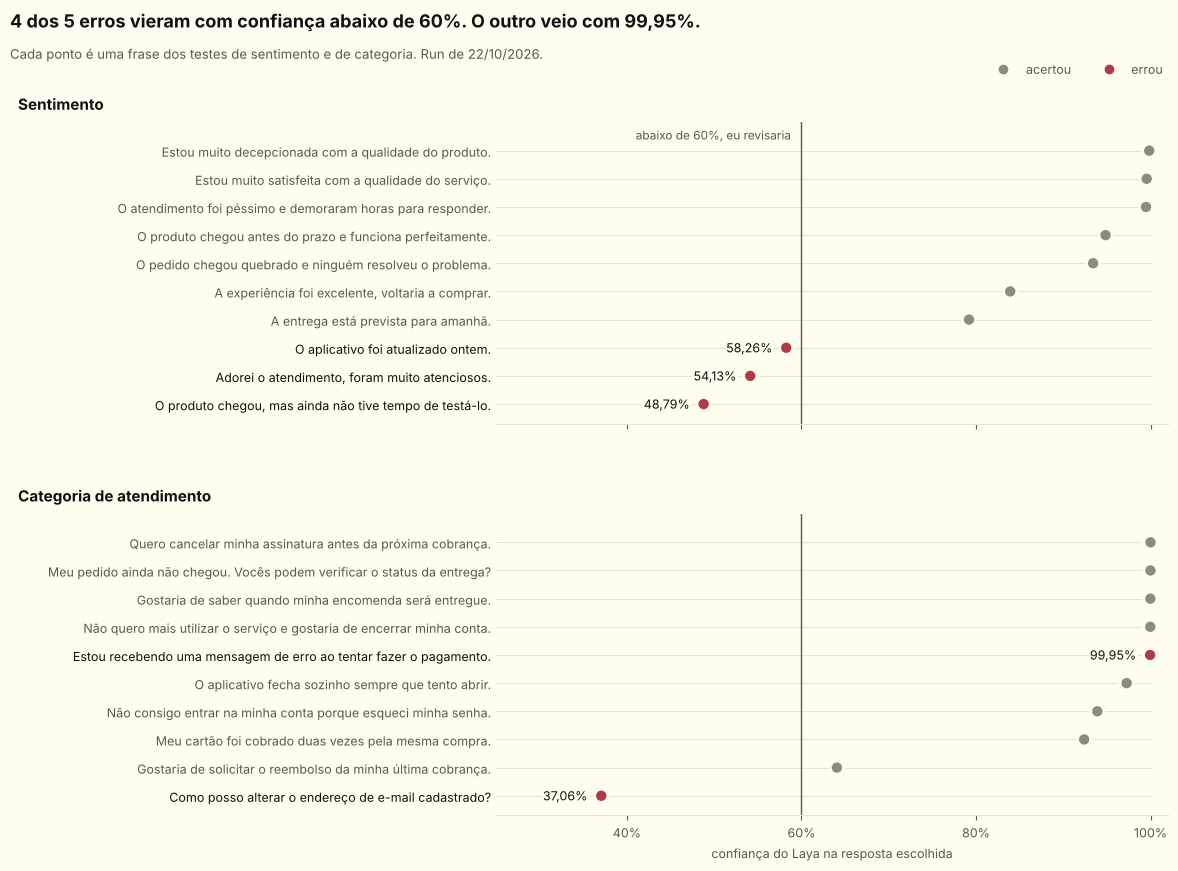

In [9]:
SUPERFICIE = "#FFFDEF"
TINTA = "#111111"
TINTA_SUAVE = "#5C584C"
GRADE = "#E9E4D0"
COR_ACERTO = "#8F8A7D"
COR_ERRO = "#B23A48"

errados = classificacao[~classificacao["Acertou"]]
abaixo = errados[errados["Confiança"] < LIMITE_REVISAO]
acima = errados[errados["Confiança"] >= LIMITE_REVISAO]
titulo = f"{len(abaixo)} dos {len(errados)} erros vieram com confiança abaixo de {LIMITE_REVISAO:.0%}."
if len(acima) == 1:
    titulo += f" O outro veio com {pct(acima['Confiança'].iloc[0])}."
elif len(acima) > 1:
    titulo += f" Os outros chegaram a {pct(acima['Confiança'].max())}."
data_run = date.fromisoformat(Path(ARQUIVO).stem.split("_")[-1]).strftime("%d/%m/%Y")

fig, eixos = plt.subplots(2, 1, figsize=(12, 9), sharex=True, facecolor=SUPERFICIE)
for eixo, (nome, tabela) in zip(eixos, [("Sentimento", sentimento), ("Categoria de atendimento", categoria)]):
    ordenada = tabela.sort_values("Confiança").reset_index(drop=True)
    eixo.set_facecolor(SUPERFICIE)
    eixo.hlines(ordenada.index, 0.25, 1.0, color=GRADE, linewidth=0.8, zorder=1)
    eixo.axvline(LIMITE_REVISAO, color=TINTA_SUAVE, linewidth=1, zorder=2)
    eixo.scatter(
        ordenada["Confiança"],
        ordenada.index,
        s=90,
        c=ordenada["Acertou"].map({True: COR_ACERTO, False: COR_ERRO}).tolist(),
        edgecolors=SUPERFICIE,
        linewidths=2,
        zorder=3,
    )
    for posicao, linha in ordenada[~ordenada["Acertou"]].iterrows():
        eixo.annotate(
            pct(linha["Confiança"]),
            (linha["Confiança"], posicao),
            xytext=(-10, 0),
            textcoords="offset points",
            ha="right",
            va="center",
            fontsize=9,
            color=TINTA,
            bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1},
            zorder=4,
        )
    eixo.set_yticks(ordenada.index, ordenada["Frase"], fontsize=9)
    for rotulo, acertou in zip(eixo.get_yticklabels(), ordenada["Acertou"]):
        rotulo.set_color(TINTA_SUAVE if acertou else TINTA)
    eixo.annotate(
        nome,
        xy=(0.015, 1.03),
        xycoords=("figure fraction", "axes fraction"),
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=TINTA,
    )
    eixo.tick_params(axis="y", length=0)
    eixo.tick_params(axis="x", colors=TINTA_SUAVE, labelsize=9)
    for lado in ("top", "right", "left"):
        eixo.spines[lado].set_visible(False)
    eixo.spines["bottom"].set_color(GRADE)
    eixo.set_ylim(-0.7, len(ordenada))

eixos[0].text(
    LIMITE_REVISAO - 0.012,
    len(sentimento) - 0.45,
    f"abaixo de {LIMITE_REVISAO:.0%}, eu revisaria",
    ha="right",
    va="center",
    fontsize=8.5,
    color=TINTA_SUAVE,
    bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1},
)
eixos[-1].set_xlim(0.25, 1.02)
eixos[-1].set_xticks([0.4, 0.6, 0.8, 1.0])
eixos[-1].xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0%}"))
eixos[-1].set_xlabel("confiança do Laya na resposta escolhida", fontsize=9, color=TINTA_SUAVE)

legenda = [
    Line2D([], [], marker="o", linestyle="none", markersize=8, markerfacecolor=cor, markeredgecolor=SUPERFICIE, label=rotulo)
    for rotulo, cor in [("acertou", COR_ACERTO), ("errou", COR_ERRO)]
]
fig.legend(handles=legenda, loc="upper right", bbox_to_anchor=(0.985, 0.93), ncols=2, frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)
fig.text(0.015, 0.975, titulo, fontsize=13, fontweight="bold", color=TINTA, ha="left", va="top")
fig.text(0.015, 0.935, f"Cada ponto é uma frase dos testes de sentimento e de categoria. Run de {data_run}.", fontsize=9.5, color=TINTA_SUAVE, ha="left", va="top")
fig.subplots_adjust(left=0.42, right=0.98, top=0.85, bottom=0.08, hspace=0.3)

Path(ARQUIVO).parent.mkdir(exist_ok=True)
fig.savefig(Path(ARQUIVO).parent / "confianca_laya.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()